# 05 · Orthology classes and accessibility at orthologs (Fig 3C-E)

Classifies every locus of each species by what its sequence ortholog shows in the other species, and draws the
accessibility of the orthologs (Fig 3C), the classes of the pdCREs (Fig 3D) and their constrained bases (Fig 3E).

1. **Background threshold**: the 95th percentile of log2 accessibility over all 500-bp bins of the genome, 2.1187 in
   mouse and 2.0779 in rabbit.
2. **Classes**: a peak whose ortholog is a peak in the other species is p2p; one whose ortholog is above the threshold
   there is p2w, and below it p2b; one without an ortholog is p2l (named p2no in the paper). The other side of p2w and
   p2b is w2p and b2p. TSS and CTCF peaks are labelled as such. The table (`orth_full_wmode_wgotg.csv`) is read by
   notebooks 06-10.
3. **Fig 3C**: accessibility at the orthologs of TSS, CTCF, pan-gastrulation and other pdCRE peaks, in rabbit (top row)
   and mouse (bottom), against the genome-wide background, with the fraction above the threshold.
4. **Fig 3D**: classes of the pdCREs of the variable CRECls.
5. **Fig 3E**: bases under constraint (phyloP >= 2.27) in the central 300 bp of these pdCREs, by class.

The grey background curves of Fig 3C are densities of 100,000 genome bins sampled at random (seed 19). In the paper,
Figs 3D and 3E are recoloured (p2b white, p2no grey).

## Setup

In [1]:
source("../R/setup.R")
out_dir = out_path("05_orthology")
O1 = file.path(OUT_DIR, "01_crecls")
O3 = file.path(OUT_DIR, "03_crecl_homology")
mm_namespace = as.data.frame(fread(data_path("mm_namespace_2025.csv")))
oc_namespace = as.data.frame(fread(data_path("oc_namespace_2025.csv")))
orth_full = fread(data_path("orth_2025.csv"))

# CRECls (notebook 01) and their classes (notebook 03)
mm_crecl = fread(file.path(O1, "mm_crecl.csv")) %>% tibble::deframe()
oc_crecl = fread(file.path(O1, "oc_crecl.csv")) %>% tibble::deframe()
crecl_classes = fread(file.path(O3, "crecl_classes.csv"), colClasses = c(crecl = "character"))
crecls_of = function(sp, cl) crecl_classes %>% filter(species == sp, class == cl) %>% pull(crecl)
mm_const_crecls = crecls_of("mouse", "pan-gastrulation")
mm_weak = crecls_of("mouse", "weak")
mm_small_crecls = crecls_of("mouse", "small")
oc_const_crecls = crecls_of("rabbit", "pan-gastrulation")
oc_weak = crecls_of("rabbit", "weak")
oc_small_crecls = crecls_of("rabbit", "small")

## 1. Background threshold

The maximum of the normalised ATAC marginal over every 500-bp bin of the genome (0 where the track has no value); the
threshold is the 95th percentile of its log2. The classes use these values rounded to four decimals.

In [2]:
mm_cov = fread(data_path("mm_genome_atac_500.csv.gz"))
oc_cov = fread(data_path("oc_genome_atac_500.csv.gz"))
mm_cov[is.na(mm_cov)] = 0
oc_cov[is.na(oc_cov)] = 0
mm_thr = quantile(log2(mm_cov$atac), 0.95, na.rm=T)
oc_thr = quantile(log2(oc_cov$atac), 0.95, na.rm=T)

mm_peak_lower_threshold = 2.1187  # mm_thr, oc_thr rounded to four decimals
oc_peak_lower_threshold = 2.0779  # multi normed by multi20k

## 2. Classes

The signal of a locus is the maximum of the same track over the 500-bp locus (0 where it has no value). TSS and CTCF peaks
then take their own label. Rows are ortholog pairs of
`orth_2025.csv` (a locus with several orthologs has several rows) and the loci of either species without one. A rabbit peak whose first row is another mouse peak's alignment, landing on it without the reciprocal match, would be
called w2p (a class for loci that are not peaks); since 2026-11-04 it takes the class of its own first row instead (811 peaks).

In [3]:
mm_locus = fread(data_path("mm_locus_atac.csv"))
oc_locus = fread(data_path("oc_locus_atac.csv"))
mm_namespace_covv = with(mm_locus, setNames(ifelse(is.na(atac), 0, atac), mm_locid))
oc_namespace_covv = with(oc_locus, setNames(ifelse(is.na(atac), 0, atac), oc_locid))
mm_tss = fread(data_path("mm_namespace_tss_only.csv"))
oc_tss = fread(data_path("oc_namespace_tss_only.csv"))
oc_tss_imgs = fread(data_path("oc_namespace_tss_imgs_only.csv"))
oc_tss_orth = fread(data_path("oc_tss_orth.csv"))
mm_ctcf = fread(data_path("mm_namespace_ctcf_only.csv"))
oc_ctcf = fread(data_path("oc_namespace_ctcf_only.csv"))

orth_full_wmode = orth_full %>% mutate(mm_mode = 'NA', oc_mode='NA') %>% mutate(mm_cov=log2(1+mm_namespace_covv[mm_locid])) %>% mutate(oc_cov=log2(1+oc_namespace_covv[oc_locid]))

# mm p2p
orth_full_wmode[
    orth_full_wmode$mm_mode == 'NA' &
    !is.na(orth_full_wmode$oc_locid) &  # mapped to oc
    !is.na(orth_full_wmode$mm_peak_id) & # peak in mm
    !is.na(orth_full_wmode$oc_peak_id) # peak in oc
    ,]$mm_mode="p2p"

#oc p2p
orth_full_wmode[
    orth_full_wmode$oc_mode == 'NA' &
    !is.na(orth_full_wmode$mm_locid) &  # mapped to mm
    !is.na(orth_full_wmode$mm_peak_id) & # peak in mm
    !is.na(orth_full_wmode$oc_peak_id) # peak in oc
    ,]$oc_mode="p2p"

# mm p2w
orth_full_wmode[
    orth_full_wmode$mm_mode == 'NA' &
    !is.na(orth_full_wmode$oc_locid) &  # mapped to oc
    !is.na(orth_full_wmode$mm_peak_id) & # peak in mm
    is.na(orth_full_wmode$oc_peak_id) &# not peak in oc
    orth_full_wmode$oc_cov >= oc_peak_lower_threshold # oc cov > bg
    ,]$mm_mode="p2w"

orth_full_wmode[
    orth_full_wmode$oc_mode == 'NA' &
    !is.na(orth_full_wmode$oc_locid) &  # mapped to oc
    !is.na(orth_full_wmode$mm_peak_id) & # peak in mm
    is.na(orth_full_wmode$oc_peak_id) &# not peak in oc
    orth_full_wmode$oc_cov >= oc_peak_lower_threshold # oc cov > bg
    ,]$oc_mode="w2p"

# oc p2w
orth_full_wmode[
    orth_full_wmode$oc_mode == 'NA' &
    !is.na(orth_full_wmode$mm_locid) &  # mapped to mm
    is.na(orth_full_wmode$mm_peak_id) & # not peak in mm
    !is.na(orth_full_wmode$oc_peak_id) & # peak in oc
    orth_full_wmode$mm_cov >= mm_peak_lower_threshold # oc cov > bg
    ,]$oc_mode="p2w"

orth_full_wmode[
    orth_full_wmode$mm_mode == 'NA' &
    !is.na(orth_full_wmode$mm_locid) &  # mapped to mm
    is.na(orth_full_wmode$mm_peak_id) & # not peak in mm
    !is.na(orth_full_wmode$oc_peak_id) & # peak in oc
    orth_full_wmode$mm_cov >= mm_peak_lower_threshold # oc cov > bg
    ,]$mm_mode="w2p"

# mm p2b
orth_full_wmode[
    orth_full_wmode$mm_mode == 'NA' &
    !is.na(orth_full_wmode$oc_locid) &  # mapped to oc
    !is.na(orth_full_wmode$mm_peak_id) & # peak in mm
    is.na(orth_full_wmode$oc_peak_id) &# not peak in oc
    orth_full_wmode$oc_cov < oc_peak_lower_threshold # oc cov > bg
    ,]$mm_mode="p2b"

orth_full_wmode[
    orth_full_wmode$oc_mode == 'NA' &
    !is.na(orth_full_wmode$oc_locid) &  # mapped to oc
    !is.na(orth_full_wmode$mm_peak_id) & # peak in mm
    is.na(orth_full_wmode$oc_peak_id) &# not peak in oc
    orth_full_wmode$oc_cov < oc_peak_lower_threshold # oc cov > bg
    ,]$oc_mode="b2p"

# oc p2b
orth_full_wmode[
    orth_full_wmode$oc_mode == 'NA' &
    !is.na(orth_full_wmode$mm_locid) &  # mapped to mm
    is.na(orth_full_wmode$mm_peak_id) & # not peak in mm
    !is.na(orth_full_wmode$oc_peak_id) & # peak in oc
    orth_full_wmode$mm_cov < mm_peak_lower_threshold # oc cov > bg
    ,]$oc_mode="p2b"

orth_full_wmode[
    orth_full_wmode$mm_mode == 'NA' &
    !is.na(orth_full_wmode$mm_locid) &  # mapped to mm
    is.na(orth_full_wmode$mm_peak_id) & # not peak in mm
    !is.na(orth_full_wmode$oc_peak_id) & # peak in oc
    orth_full_wmode$mm_cov < mm_peak_lower_threshold # oc cov > bg
    ,]$mm_mode="b2p"

# mm p2l
orth_full_wmode[
    orth_full_wmode$mm_mode == 'NA' &
    is.na(orth_full_wmode$oc_locid) &  # not mapped to oc
    !is.na(orth_full_wmode$mm_peak_id) # peak in mm
    ,]$mm_mode="p2l"

# oc p2l
orth_full_wmode[
    orth_full_wmode$oc_mode == 'NA' &
    is.na(orth_full_wmode$mm_locid) &  # not mapped to mm
    !is.na(orth_full_wmode$oc_peak_id) # peak in oc
    ,]$oc_mode="p2l"

mm_mode = orth_full_wmode$mm_mode
names(mm_mode) = orth_full_wmode$mm_locid
oc_mode = orth_full_wmode$oc_mode
names(oc_mode) = orth_full_wmode$oc_locid
mm_mode[mm_ctcf$mm_locid] = "ctcf"
oc_mode[oc_ctcf$oc_locid] = "ctcf"
mm_mode[mm_tss$mm_locid] = "tss"
oc_mode[union(union(oc_tss$oc_locid, oc_tss_orth$oc_locid), oc_tss_imgs$oc_locid)] = "tss"
orth_full_wmode$mm_mode = mm_mode[orth_full_wmode$mm_locid]
orth_full_wmode$oc_mode = oc_mode[orth_full_wmode$oc_locid]

# Rabbit peaks whose first row is another mouse peak's alignment landing on them without the reciprocal match (oc_peak_id empty in
# that row) get "w2p" from the rabbit-side rules above, a class meant for rabbit loci that are not peaks. Fix (2026-11-04): such a
# peak takes the class of its own first row (the first row carrying its oc_peak_id), by the same rules: p2l without a mouse
# ortholog, p2p when the mouse ortholog is a peak, otherwise p2w / p2b by the mouse signal. 811 rabbit peaks change; no other locus.
own = orth_full_wmode[!is.na(orth_full_wmode$oc_peak_id), ]
own = own[!duplicated(own$oc_locid), ]
own_class = with(own, ifelse(is.na(mm_locid), "p2l", ifelse(!is.na(mm_peak_id), "p2p",
                 ifelse(mm_cov >= mm_peak_lower_threshold, "p2w", "p2b"))))
names(own_class) = own$oc_locid
fix_rows = which(orth_full_wmode$oc_mode %in% c("w2p", "b2p") & orth_full_wmode$oc_locid %in% names(own_class))
stopifnot(!anyNA(own_class[orth_full_wmode$oc_locid[fix_rows]]))
orth_full_wmode$oc_mode[fix_rows] = unname(own_class[orth_full_wmode$oc_locid[fix_rows]])

fwrite(orth_full_wmode, file.path(out_dir, "orth_full_wmode_wgotg.csv"))

## 3. Fig 3C

Accessibility (log2 of the locus signal) at the orthologs of four sets of peaks, in the other species: TSS, CTCF,
pan-gastrulation pdCREs (the pdCREs of the pan-gastrulation CRECls) and pdCREs (all CRECls except the weak ones). Each
panel gives the number of orthologs (n), the fraction above the threshold (dashed line) and, in grey, the genome-wide
background. Per set, first the mouse accessibility at the orthologs of rabbit peaks (bottom row of the figure), then the
rabbit accessibility at the orthologs of mouse peaks (top row).

In [4]:
# the tables and CRECl lists of the panels
orth = orth_full_wmode
orth_full$mm_km = mm_crecl[orth_full$mm_locid]
orth_full$oc_km = oc_crecl[orth_full$oc_locid]
mm_vclst_nmc = setdiff(as.character(1:100), c(mm_weak))
oc_vclst_nmc = setdiff(as.character(1:100), c(oc_weak))
mm_pan = mm_const_crecls
oc_pan = oc_const_crecls
ctcf_col = rgb(0/255, 176/255, 240/255)

# the locus signal, 0 where missing in mouse; rabbit loci without a value are left out
mm_namespace_covv = with(mm_locus, setNames(ifelse(is.na(atac), 0, atac), mm_locid))
oc_namespace_covv = with(oc_locus, setNames(atac, oc_locid))

# the background, 100,000 genome bins
set.seed(19)
mm_sampled = mm_cov %>% select(mm_atac = atac) %>% sample_n(100000)
oc_sampled = oc_cov %>% select(oc_atac = atac) %>% sample_n(100000)

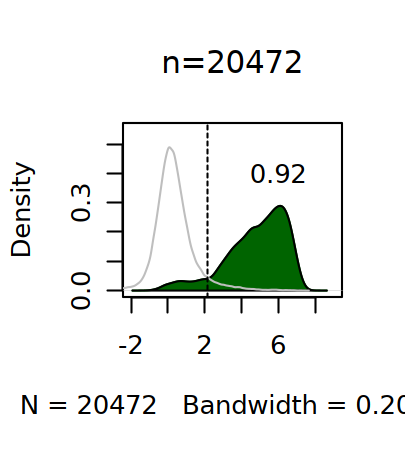

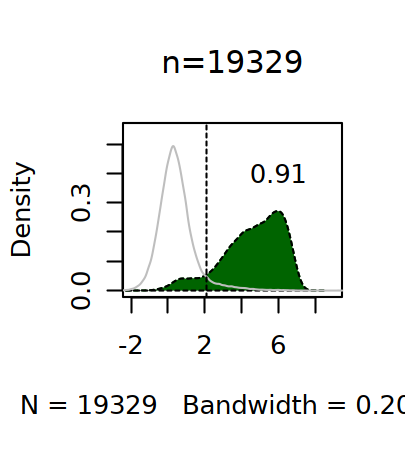

In [5]:
options(repr.plot.width = 2.7, repr.plot.height = 3)
mm_tab = table(log2(mm_namespace_covv[orth %>% filter(!is.na(oc_peak_id)) %>% filter(oc_mode=="tss") %>% filter(!is.na(mm_locid)) %>% group_by(oc_locid) %>% arrange(-mm_namespace_covv[mm_locid]) %>% slice(1) %>% pull(mm_locid)]) >= mm_thr)
title=round((mm_tab/sum(mm_tab))[2], digits = 2)
plot(density(log2(mm_namespace_covv[orth %>% filter(!is.na(oc_peak_id)) %>% filter(oc_mode=="tss") %>% filter(!is.na(mm_locid)) %>% group_by(oc_locid) %>% arrange(-mm_namespace_covv[mm_locid]) %>% slice(1) %>% pull(mm_locid)]), na.rm=T), col="darkgreen", xlim=c(-2,9), ylim=c(0,0.55), main=paste0('n=', sum(mm_tab)))
polygon(density(log2(mm_namespace_covv[orth %>% filter(!is.na(oc_peak_id)) %>% filter(oc_mode=="tss") %>% filter(!is.na(mm_locid))  %>% group_by(oc_locid) %>% arrange(-mm_namespace_covv[mm_locid]) %>% slice(1) %>% pull(mm_locid)]), na.rm=T), col = "darkgreen")
lines(density(log2(mm_sampled$mm_atac), na.rm=T), col="grey")
text(title, x=6, y=0.4)
abline(v=mm_thr, lty=2)

oc_tab = table(log2(oc_namespace_covv[orth %>% filter(!is.na(mm_peak_id)) %>% filter(mm_mode=="tss") %>% filter(!is.na(oc_locid)) %>% group_by(mm_locid) %>% arrange(-oc_namespace_covv[oc_locid]) %>% slice(1) %>% pull(oc_locid)]) >= oc_thr)
title=round((oc_tab/sum(oc_tab))[2], digits = 2)
plot(density(log2(oc_namespace_covv[orth %>% filter(!is.na(mm_peak_id)) %>% filter(mm_mode=="tss") %>% filter(!is.na(oc_locid)) %>% group_by(mm_locid) %>% arrange(-oc_namespace_covv[oc_locid]) %>% slice(1) %>% pull(oc_locid)]), na.rm=T), lty=2, col="darkgreen", xlim=c(-2,9), ylim=c(0,0.55), main=paste0('n=', sum(oc_tab)))
polygon(density(log2(oc_namespace_covv[orth %>% filter(!is.na(mm_peak_id)) %>% filter(mm_mode=="tss") %>% filter(!is.na(oc_locid)) %>% group_by(mm_locid) %>% arrange(-oc_namespace_covv[oc_locid]) %>% slice(1) %>% pull(oc_locid)]), na.rm=T), lty=2, col="darkgreen")
lines(density(log2(oc_sampled$oc_atac), na.rm=T), col="grey")
text(title, x=6, y=0.4)
abline(v=oc_thr, lty=2)

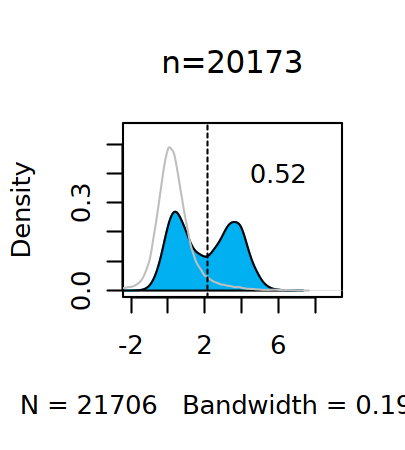

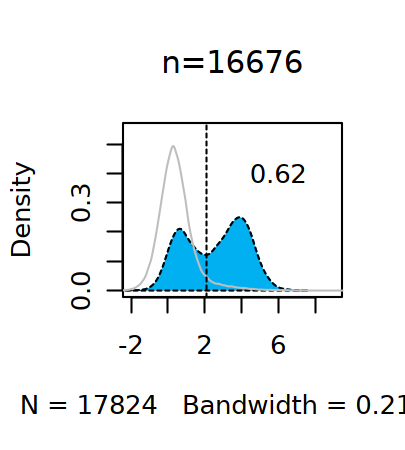

In [6]:
options(repr.plot.width = 2.7, repr.plot.height = 3)
mm_tab = table(log2(mm_namespace_covv[orth %>% filter(!is.na(oc_peak_id)) %>% filter(oc_mode=="ctcf") %>% filter(!is.na(mm_locid)) %>% group_by(oc_locid) %>% arrange(-mm_namespace_covv[mm_locid]) %>% slice(1) %>% pull(mm_locid)]) >= mm_thr)
title=round((mm_tab/sum(mm_tab))[2], digits = 2)
plot(density(log2(mm_namespace_covv[orth %>% filter(!is.na(oc_peak_id)) %>% filter(oc_mode=="ctcf") %>% filter(!is.na(mm_locid)) %>% pull(mm_locid)]), na.rm=T), col=ctcf_col, xlim=c(-2,9), ylim=c(0,0.55), main=paste0('n=', sum(mm_tab)))
polygon(density(log2(mm_namespace_covv[orth %>% filter(!is.na(oc_peak_id)) %>% filter(oc_mode=="ctcf") %>% filter(!is.na(mm_locid)) %>% pull(mm_locid)]), na.rm=T), col = ctcf_col)
lines(density(log2(mm_sampled$mm_atac), na.rm=T), col="grey")
text(title, x=6, y=0.4)
abline(v=mm_thr, lty=2)

oc_tab = table(log2(oc_namespace_covv[orth %>% filter(!is.na(mm_peak_id)) %>% filter(mm_mode=="ctcf") %>% filter(!is.na(oc_locid)) %>% group_by(mm_locid) %>% arrange(-oc_namespace_covv[oc_locid]) %>% slice(1) %>% pull(oc_locid)]) >= oc_thr)
title=round((oc_tab/sum(oc_tab))[2], digits = 2)
plot(density(log2(oc_namespace_covv[orth %>% filter(!is.na(mm_peak_id)) %>% filter(mm_mode=="ctcf") %>% filter(!is.na(oc_locid)) %>% pull(oc_locid)]), na.rm=T), lty=2, col=ctcf_col, xlim=c(-2,9), ylim=c(0,0.55), main=paste0('n=', sum(oc_tab)))
polygon(density(log2(oc_namespace_covv[orth %>% filter(!is.na(mm_peak_id)) %>% filter(mm_mode=="ctcf") %>% filter(!is.na(oc_locid)) %>% pull(oc_locid)]), na.rm=T), lty=2, col=ctcf_col)
lines(density(log2(oc_sampled$oc_atac), na.rm=T), col="grey")
text(title, x=6, y=0.4)
abline(v=oc_thr, lty=2)

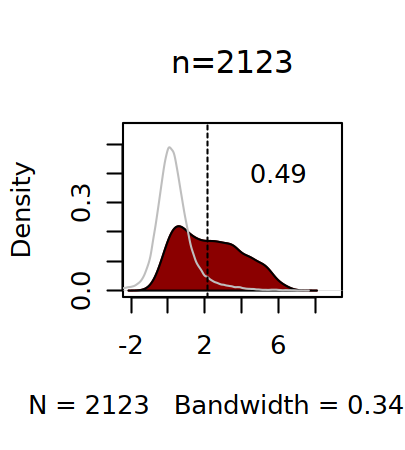

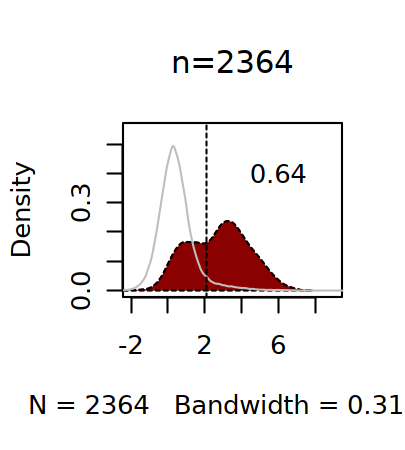

In [7]:
options(repr.plot.width = 2.7, repr.plot.height = 3)
mm_tab = table(log2(mm_namespace_covv[orth_full %>% filter(!is.na(oc_peak_id)) %>% filter(!is.na(oc_km) & oc_km %in% oc_pan) %>% filter(!is.na(mm_locid)) %>% pull(mm_locid)]) >= mm_thr)
title=round((mm_tab/sum(mm_tab))[2], digits = 2)

plot(density(log2(mm_namespace_covv[orth_full %>% filter(!is.na(oc_peak_id)) %>% filter(!is.na(oc_km) & oc_km %in% oc_pan) %>% filter(!is.na(mm_locid)) %>% pull(mm_locid)]), na.rm=T), col="darkred", xlim=c(-2,9), ylim=c(0,0.55), main=paste0('n=', sum(mm_tab)))
polygon(density(log2(mm_namespace_covv[orth_full %>% filter(!is.na(oc_peak_id)) %>% filter(!is.na(oc_km) & oc_km %in% oc_pan) %>% filter(!is.na(mm_locid)) %>% pull(mm_locid)]), na.rm=T), col = "darkred")
lines(density(log2(mm_sampled$mm_atac)), col="grey")
text(title, x=6, y=0.4)
abline(v=mm_thr, lty=2)

oc_tab = table(log2(oc_namespace_covv[orth_full %>% filter(!is.na(mm_peak_id)) %>% filter(!is.na(mm_km) & mm_km %in% mm_pan) %>% filter(!is.na(oc_locid)) %>% pull(oc_locid)]) >= oc_thr)
title=round((oc_tab/sum(oc_tab))[2], digits = 2)
plot(density(log2(oc_namespace_covv[orth_full %>% filter(!is.na(mm_peak_id)) %>% filter(!is.na(mm_km) & mm_km %in% mm_pan) %>% filter(!is.na(oc_locid)) %>% pull(oc_locid)]), na.rm=T), lty=2, col="darkred", xlim=c(-2,9), ylim=c(0,0.55), main=paste0('n=', sum(oc_tab)))
polygon(density(log2(oc_namespace_covv[orth_full %>% filter(!is.na(mm_peak_id)) %>% filter(!is.na(mm_km) & mm_km %in% mm_pan) %>% filter(!is.na(oc_locid)) %>% pull(oc_locid)]), na.rm=T), lty=2, col="darkred")
lines(density(log2(oc_sampled$oc_atac), na.rm=T), col="grey")
text(title, x=6, y=0.4)
abline(v=oc_thr, lty=2)

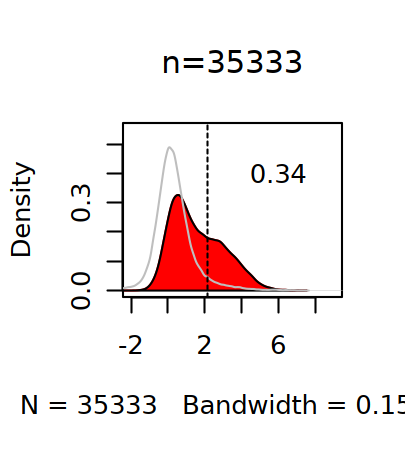

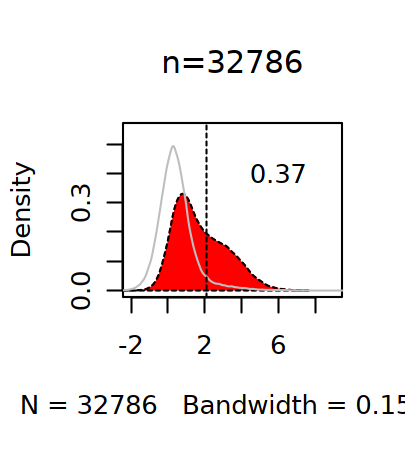

In [8]:
options(repr.plot.width = 2.7, repr.plot.height = 3)
mm_tab = table(log2(mm_namespace_covv[orth_full %>% filter(!is.na(oc_peak_id)) %>% filter(!is.na(oc_km) & oc_km %in% oc_vclst_nmc) %>% filter(!is.na(mm_locid)) %>% pull(mm_locid)]) >= mm_thr)
title=round((mm_tab/sum(mm_tab))[2], digits = 2)
plot(density(log2(mm_namespace_covv[orth_full %>% filter(!is.na(oc_peak_id)) %>% filter(!is.na(oc_km) & oc_km %in% oc_vclst_nmc) %>% filter(!is.na(mm_locid)) %>% pull(mm_locid)]), na.rm=T), col="red", xlim=c(-2,9), ylim=c(0,0.55), main=paste0('n=', sum(mm_tab)))
polygon(density(log2(mm_namespace_covv[orth_full %>% filter(!is.na(oc_peak_id)) %>% filter(!is.na(oc_km) & oc_km %in% oc_vclst_nmc) %>% filter(!is.na(mm_locid)) %>% pull(mm_locid)]), na.rm=T), col = "red")
lines(density(log2(mm_sampled$mm_atac)), col="grey")
text(title, x=6, y=0.4)
abline(v=mm_thr, lty=2)

oc_tab = table(log2(oc_namespace_covv[orth_full %>% filter(!is.na(mm_peak_id)) %>% filter(!is.na(mm_km) & mm_km %in% mm_vclst_nmc) %>% filter(!is.na(oc_locid)) %>% pull(oc_locid)]) >= oc_thr)
title=round((oc_tab/sum(oc_tab))[2], digits = 2)
plot(density(log2(oc_namespace_covv[orth_full %>% filter(!is.na(mm_peak_id)) %>% filter(!is.na(mm_km) & mm_km %in% mm_vclst_nmc) %>% filter(!is.na(oc_locid)) %>% pull(oc_locid)]), na.rm=T), lty=2, col="red", xlim=c(-2,9), ylim=c(0,0.55), main=paste0('n=', sum(oc_tab)))
polygon(density(log2(oc_namespace_covv[orth_full %>% filter(!is.na(mm_peak_id)) %>% filter(!is.na(mm_km) & mm_km %in% mm_vclst_nmc) %>% filter(!is.na(oc_locid)) %>% pull(oc_locid)]), na.rm=T), lty=2, col="red")
lines(density(log2(oc_sampled$oc_atac), na.rm=T), col="grey")
text(title, x=6, y=0.4)
abline(v=oc_thr, lty=2)

## 4. Fig 3D

Classes of the pdCREs of the variable CRECls; a locus takes the class of its first row in the table.

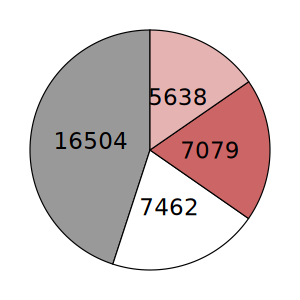

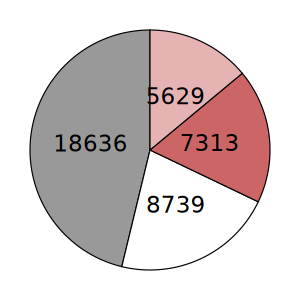

In [9]:
mm_vclst_nmc = setdiff(as.character(1:100), c(mm_const_crecls, mm_weak, mm_small_crecls))
oc_vclst_nmc = setdiff(as.character(1:100), c(oc_const_crecls, oc_weak, oc_small_crecls))
mm_namespace_f = mm_namespace %>% filter(mm_locid %in% orth_full_wmode$mm_locid)
oc_namespace_f = oc_namespace %>% filter(oc_locid %in% orth_full_wmode$oc_locid)
mm_mode = orth_full_wmode$mm_mode
names(mm_mode) = orth_full_wmode$mm_locid
oc_mode = orth_full_wmode$oc_mode
names(oc_mode) = orth_full_wmode$oc_locid
mm_namespace_f$crecl = mm_crecl[mm_namespace_f$mm_locid]
mm_namespace_f$mode = mm_mode[mm_namespace_f$mm_locid]
oc_namespace_f$crecl = oc_crecl[oc_namespace_f$oc_locid]
oc_namespace_f$mode = oc_mode[oc_namespace_f$oc_locid]
catcols = c(
    "p2p"="#CC6666",  # Muted, desaturated red
    "p2w"="#E6B3B3",  # Soft, muted pink
    "p2b"="#999999",  # Neutral grey
    "p2l"="#FFFFFF"   # White
)

options(repr.plot.width = 2, repr.plot.height = 2)
p = mm_namespace_f %>%
  filter(!is.na(crecl) & crecl %in% mm_vclst_nmc) %>%
  filter(mode %in% c("p2p", "p2w", "p2b", "p2l")) %>%
  group_by(mode) %>%
  summarise(n = n()) %>%
  ggplot(aes(x = "", y = n, fill = mode)) +
  geom_bar(stat = "identity", width = 1, color = "black", linewidth = 0.2) +
  scale_fill_manual(values = catcols, breaks = catcols, labels = names(catcols)) +
  coord_polar("y") +
  theme_void() +
  geom_text(aes(label = n), position = position_stack(vjust = 0.5))
print(p)

p = oc_namespace_f %>% filter(!is.na(crecl)& crecl %in% oc_vclst_nmc) %>% filter(mode %in% c("p2p", "p2w", "p2b", "p2l")) %>% group_by(mode) %>% summarise(n=n()) %>%   ggplot(aes(x = "", y = n, fill = mode)) +
  geom_bar(stat = "identity", width = 1, color = "black", linewidth = 0.2) +
  scale_fill_manual(values = catcols, breaks = catcols, labels = names(catcols)) +
  coord_polar("y") +
  theme_void() +
  geom_text(aes(label = n), position = position_stack(vjust = 0.5))
print(p)

## 5. Fig 3E

Bases with phyloP >= 2.27 in the central 300 bp of the pdCREs of the variable CRECls, binned, by class. Only the p2p, p2w
and p2b panels have pdCREs: TSS and CTCF peaks are not in CRECls.

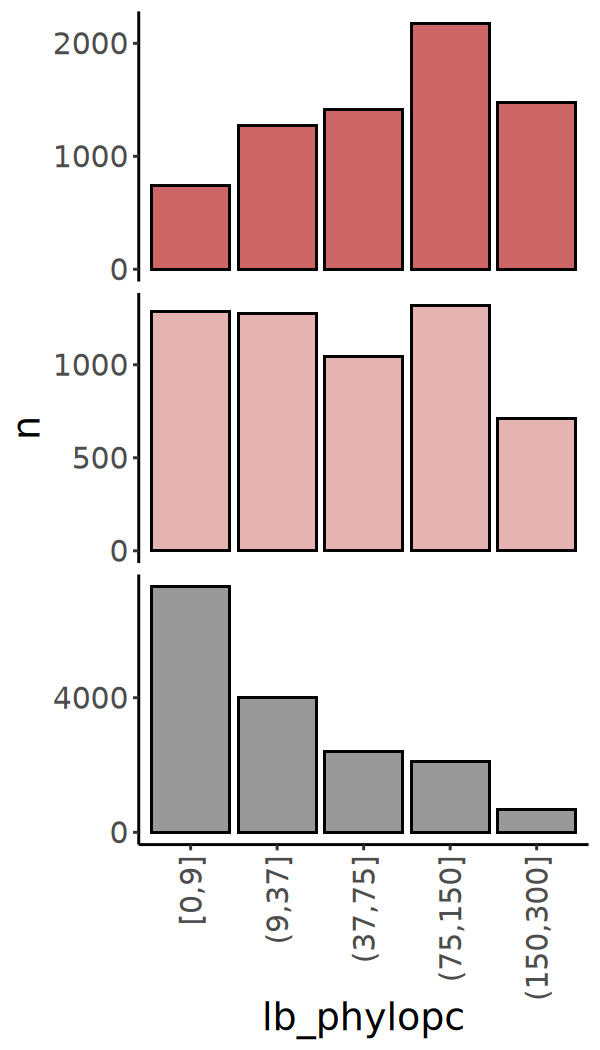

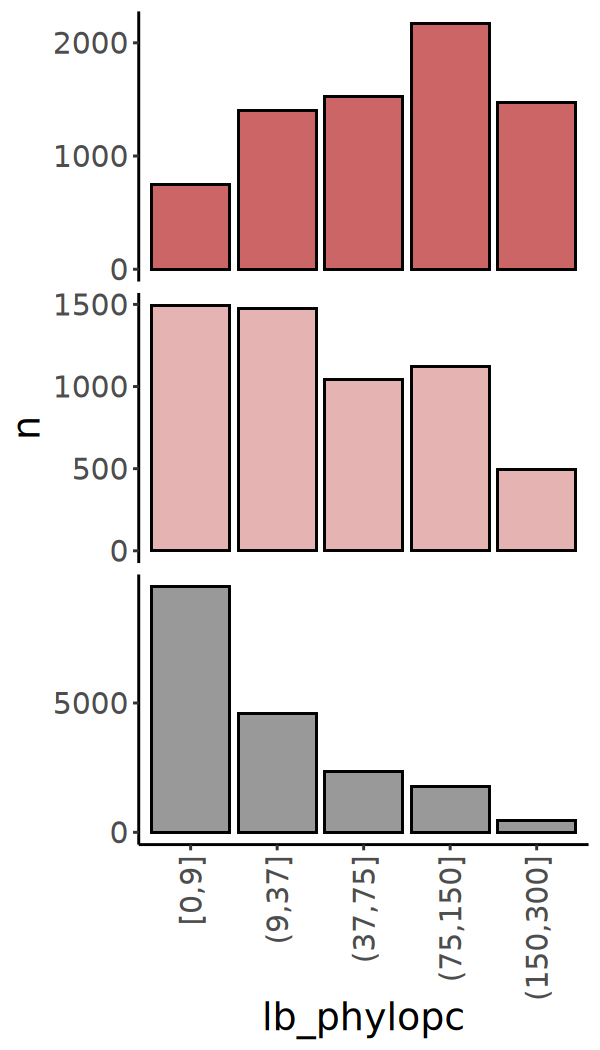

In [10]:
mm_loci_cons = fread(data_path("mm_locus_phylop.csv"))
oc_loci_cons = fread(data_path("oc_locus_phylop.csv"))
bins = c(0L, 9L, 37L, 75L, 150L, 300L)
mm_loci_cons_binned = mm_loci_cons %>% mutate(lb_phylopc = cut(phyloP05, n = length(bins), breaks = bins, include.lowest = T))
oc_loci_cons_binned = oc_loci_cons %>% mutate(lb_phylopc = cut(phyloP05, n = length(bins), breaks = bins, include.lowest = T))

constraint_plot = function(namespace_f, vclst, loci_cons_binned, id) {
    namespace_f %>%
      filter(!is.na(crecl) & crecl %in% vclst) %>%
      left_join(loci_cons_binned, by = id) %>%
      filter(mode %in% c("tss", "ctcf", "p2p", "p2w", "p2b")) %>%
      mutate(mode = factor(mode, levels = c("tss", "ctcf", "p2p", "p2w", "p2b"))) %>%
      group_by(mode, lb_phylopc) %>%
      summarise(n = n(), .groups = "drop") %>%
      ggplot(aes(x = lb_phylopc, y = n, fill = mode, color = "black")) +
      geom_bar(stat = "identity") +
      facet_wrap(~mode, ncol = 1, scales = "free_y") +
      scale_fill_manual(values = catcols, breaks = catcols, labels = names(catcols)) +
      scale_color_identity() +
      scale_y_continuous(n.breaks = 3) +
      theme(
        panel.grid.major = element_blank(),
        panel.grid.minor = element_blank(),
        panel.background = element_blank(),
        axis.line = element_line(color = "black"),
        strip.text = element_blank(),
        strip.background = element_blank(),
        text = element_text(size = 18),
        axis.text.x = element_text(angle = 90, vjust = 0.5, hjust = 1, size = 14),
        axis.text.y = element_text(size = 14)
      )
}
options(repr.plot.width = 4, repr.plot.height = 7)
print(constraint_plot(mm_namespace_f, mm_vclst_nmc, mm_loci_cons_binned, "mm_locid"))
print(constraint_plot(oc_namespace_f, oc_vclst_nmc, oc_loci_cons_binned, "oc_locid"))